# **QAOA for Order-8 Williamson-type Hadamard Matrix**

### **Abstract**
This notebook demonstrates the application of the Quantum Approximate Optimization Algorithm `(QAOA)` to construct an Order-8 Williamson-type Hadamard matrix. The Williamson construction is a method for generating Hadamard matrices, which are square matrices with entries of $\pm1$ and satisfy orthogonality conditions. The goal of this notebook is to use QAOA to find a valid Hadamard matrix of order 8.

A Williamson-type Hadamard matrix of order 8 can be constructed using four sequences of length 8, denoted as $A, B, C$, and $D$. Each sequence consists of elements from the set $\{+1, -1\}$. The sequences must satisfy specific orthogonality conditions to ensure that the resulting Hadamard matrix is valid:
$$AA^T + BB^T + CC^T + DD^T = 4nI_8$$
where $n=2$ for order 8, and $I_8$ is the identity matrix of order 8.

The problem is formulated as a Hamiltonian minimization problem, where the objective is to minimize the energy of the system while satisfying the orthogonality constraints. The QAOA algorithm is employed to find the optimal sequences $A, B, C$, and $D$ that yield a valid Williamson-type Hadamard matrix of order 8.
The orthogonality condition is as follows:
$$HH^T = 8I_8$$

### **Introduction**

- Williamson Construction

For Order-8, the Williamson $N=4n$ and $n=2$, we construct $A, B, C, D$ as symmetric circulant matrices. The Williamson matrix is:
$$H = \begin{bmatrix}
A & B & C & D \\
-B & A & -D & C \\
-C & D & A & -B \\
-D & -C & B & A
\end{bmatrix}$$

### **Install and Import Required Libraries**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from sympy import symbols
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.visualization import plot_bloch_multivector, plot_histogram

/var/folders/_t/q_d36zn17wv0qrfmtywnt18c0000gn/T/ipykernel_23152/1637517495.py:6: DeprecationWarning: Using Qiskit with Python 3.9 is deprecated as of the 2.1.0 release. Support for running Qiskit with Python 3.9 will be removed in the 2.3.0 release, which coincides with when Python 3.9 goes end of life.
  from qiskit import QuantumCircuit


### **Global Variables**

```python
vObj =[]        # Objective Value
vShots = []     # Number of shots
vCorrect = []   # Number of correct shots
GEN_SOL = []    # Generated Solution
```

In [2]:
vObj =[]        # Objective Value
vShots = []     # Number of shots
vCorrect = []   # Number of correct shots
GEN_SOL = []    # Generated Solution

### **Binary ⇒ Spin Conversion**
QAOA measures bitstrings $x_i \in \{0,1\}$ while the Ising Hamiltonain uses spins $s_i \in \{-1,1\}$. The conversion is as follows:
$$s_i = 1 - 2x_i$$
or 
$$0 \rightarrow +1$$
$$1 \rightarrow -1$$

In [3]:
def binary_to_spin(x):
    if x == 0:
        return 1
    elif x == 1:
        return -1

### **Order-8 Williamson-type Hadamard Matrix Variables**

For $n=2$, each symmetric circulant matrix $A, B, C, D$ is determined by one independent variable:
$$A = (a, b)$$
$$B = (c, d)$$
$$C = (e, f)$$
$$D = (g, h)$$

Thus only four independent variables are required $s_0, s_1, s_2, s_3$.

### **Williamson Hamiltonian**

For order-8 Williamson-type Hadamard matrix, the Williamson condition becomes:
$$s_0 + s_1 + s_2 + s_3 = 0$$

The corresponding cost Hamiltonian is:
$$H_C = (s_0 + s_1 + s_2 + s_3)^2$$
Expanding this, we get:
$$H_C = s_0^2 + s_1^2 + s_2^2 + s_3^2 + 2(s_0s_1 + s_0s_2 + s_0s_3 + s_1s_2 + s_1s_3 + s_2s_3)$$

But since $s_i^2 = 1$ for all $i$, we can simplify this to:
$$H_C = 4 + 2(s_0s_1 + s_0s_2 + s_0s_3 + s_1s_2 + s_1s_3 + s_2s_3)$$

### **Objective Function**

In [4]:
def obj_williamson_8(bitstring):

    s0 = binary_to_spin(int(bitstring[0]))  # int means convert from string to integer
    s1 = binary_to_spin(int(bitstring[1]))
    s2 = binary_to_spin(int(bitstring[2]))
    s3 = binary_to_spin(int(bitstring[3]))

    # Objective function for Williamson-type Hadamard matrix of order 8
    obj = (
        4 + 
        2 * (s0 * s1 + s0 * s2 + s0 * s3 + s1 * s2 + s1 * s3 + s2 * s3)
    )

    return obj

### **Candidate Evaluation Function**

In [5]:
def hadamard_obj(bitstring):
    # Evaluate the objective function for Williamson-type Hadamard matrix of order 8
    obj = obj_williamson_8(bitstring)

    found = 0

    if abs(obj) < 1e-8:
        found = 1
        GEN_SOL.append(bitstring)


    return obj, found

### **Expectation Value**

In [6]:
def compute_expectation_value(counts):

    avg = 0
    total = 0

    for bitstring, count in counts.items():
        obj, found = hadamard_obj(bitstring)
        avg += obj * count
        total += count

        return avg / total
    

### **Cost Unitary**
For each Hamiltonian term, $cZ_iZ_j$, QAOA applies a unitary $e^{-i\gamma Z_iZ_j}$

In [7]:
def U_C_2body(qc, c, gamma, qbs):
    """
    Apply the cost unitary for a 2-body Hamiltonian term c*Z_i*Z_j
    """
    qc.cx(qbs[0], qbs[1])           # Apply CNOT gate with qbs[0] as control and qbs[1] as target
    qc.rz(-2 * gamma * c, qbs[1])   # Apply Rz rotation on qbs[1] with angle -2*gamma*c
    qc.cx(qbs[0], qbs[1])           # Apply CNOT gate again to disentangle the qubits

### **Hamiltonian Terms**

In [8]:
qx = [
    [2, [0, 1]],    # Hamiltonian term cZ0Z1
    [2, [0, 2]],    # Hamiltonian term cZ0Z2
    [2, [0, 3]],    # Hamiltonian term cZ0Z3
    [2, [1, 2]],    # Hamiltonian term cZ1Z2
    [2, [1, 3]],    # Hamiltonian term cZ1Z3
    [2, [2, 3]]     # Hamiltonian term cZ2Z3
]

### **Construct QAOA Circuit**

In [9]:
def create_qaoa_circuit(qx, nqubits, theta):
    """
    Create a QAOA circuit with length 'p' and angle 'theta'.
    """
    p = len(theta) // 2  # Number of layers
    beta = theta[:p]      # First half of theta corresponds to beta angles
    gamma = theta[p:]     # Second half of theta corresponds to gamma angles

    qc = QuantumCircuit(nqubits)  # Create a quantum circuit with nqubits

    for q in range(nqubits):
        qc.h(q)  # Apply Hadamard gate to each qubit to create superposition

    for layer in range(p):
        for coeff, qbs, in qx:
            U_C_2body(qc, coeff, gamma[layer], qbs)  # Apply cost unitary for each Hamiltonian term

        for q in range(nqubits):
            qc.rx(2 * beta[layer], q)  # Apply Rx rotation on each qubit

    # Measure all qubits
    qc.measure_all()

    return qc

### **Backend**

In [10]:
backend = Aer.get_backend('qasm_simulator')  # Use the QASM simulator backend from Qiskit Aer
shots = 1024 # Number of shots for the simulation

### **Optimization Objective**

In [11]:
def get_expectation_value(theta):
    
    def execute(theta): 
        qc = create_qaoa_circuit(qx, 4, theta)  # Create the QAOA circuit with 4 qubits and given theta
        counts = backend.run(qc, shots=shots).result().get_counts()  # Execute the circuit and get counts

        value = compute_expectation_value(counts)  # Compute the expectation value from the counts

        vObj.append(value)  # Append the computed expectation value to the list vObj
        vShots.append(shots)  # Append the number of shots to the list vShots
        vCorrect.append(sum(hadamard_obj(bitstring)[1] * count for bitstring, count in counts.items()))  # Append the number of correct shots to vCorrect
        return value

    return execute

### **Classical Optimization**

In [12]:
Nlayers = 1  # Number of QAOA layers
theta0 = np.random.uniform(-1, 1, 2 * Nlayers)  # Random initial angles for optimization between -1 and 1 for both beta and gamma angles

expectation = get_expectation_value(theta0)

res = minimize(expectation, theta0, 
            #    method='COBYLA',
              method='Nelder-Mead', 
            #    options={'maxiter': 100})
              options={'maxiter': 1000})


print("Optimization Result:", res)  # Print the optimization result, which includes optimized angles and expectation value
print("Optimized angles:", res.x)           #res.x means  the x value of the optimization result, which corresponds to the optimized parameters (angles) for the QAOA circuit.
print("Optimized expectation value:", res.fun) #res.fun means the y value of the optimization result, which corresponds to the optimized expectation value for the QAOA circuit

Optimization Result:        message: Optimization terminated successfully.
       success: True
        status: 0
           fun: 0.0
             x: [-9.529e-01  4.749e-01]
           nit: 10
          nfev: 37
 final_simplex: (array([[-9.529e-01,  4.749e-01],
                       [-9.529e-01,  4.750e-01],
                       [-9.528e-01,  4.750e-01]]), array([ 0.000e+00,  0.000e+00,  0.000e+00]))
Optimized angles: [-0.95290663  0.47491307]
Optimized expectation value: 0.0


### **Final QAOA Circuit**

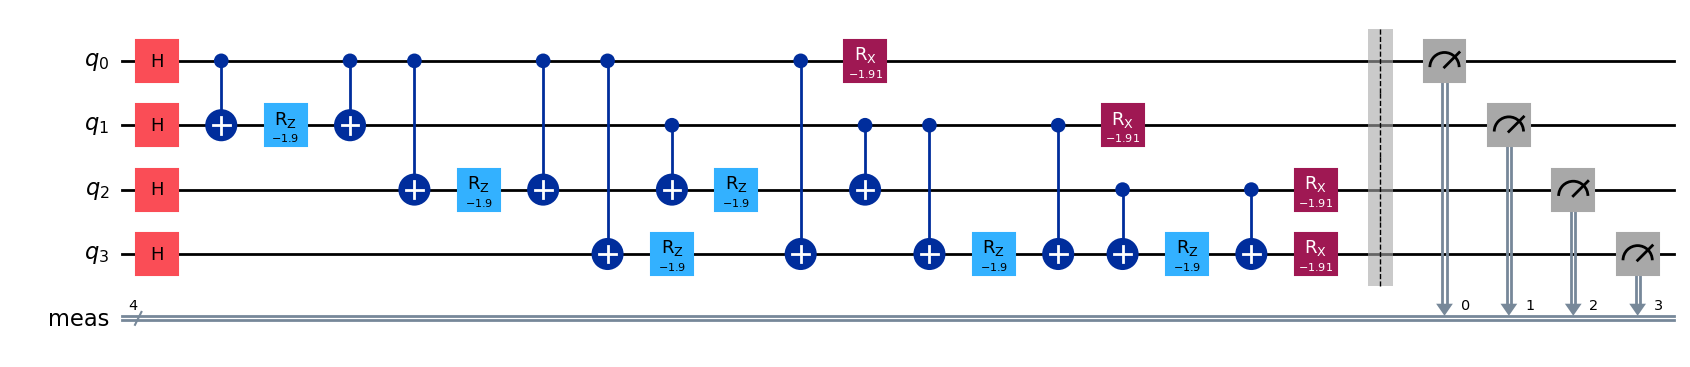

In [13]:
theta_opt = res.x  # Store the optimized angles from the optimization result

qc_final = create_qaoa_circuit(qx, 4, theta_opt)  # Create the final QAOA circuit using the optimized angles

qc_final.draw('mpl')  # Draw the final QAOA circuit using matplotlib

### **Histogram of Top 10 Shots**

{'0101': 5, '0110': 3, '1001': 7, '1010': 6, '0001': 129, '0011': 8, '1101': 104, '1111': 67, '0111': 95, '1011': 109, '1000': 109, '1110': 107, '1100': 1, '0100': 104, '0000': 67, '0010': 103}
Top 10 counts: {'0001': 129, '1011': 109, '1000': 109, '1110': 107, '1101': 104, '0100': 104, '0010': 103, '0111': 95, '1111': 67, '0000': 67}


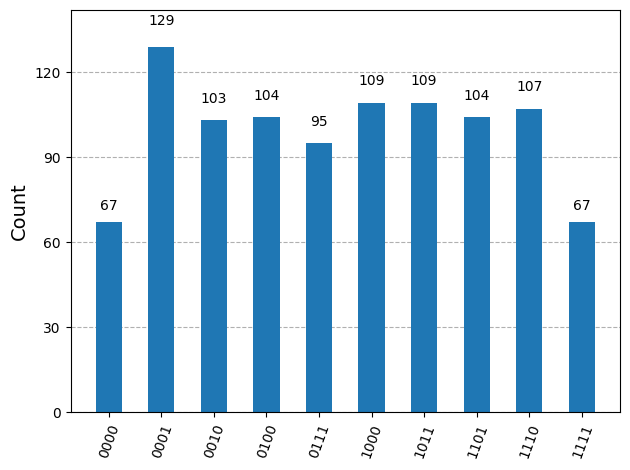

In [14]:
counts = backend.run(qc_final, shots=shots).result().get_counts()  # Execute the final QAOA circuit and get counts
print(counts)

top_10_counts = dict(sorted(counts.items(), key=lambda item: item[1], reverse=True)[:10])  # Get the top 10 counts
print("Top 10 counts:", top_10_counts)

display(plot_histogram(top_10_counts))  # Display a histogram of the top 10 counts using Qiskit's plot_histogram function

### **Convergence Analysis**

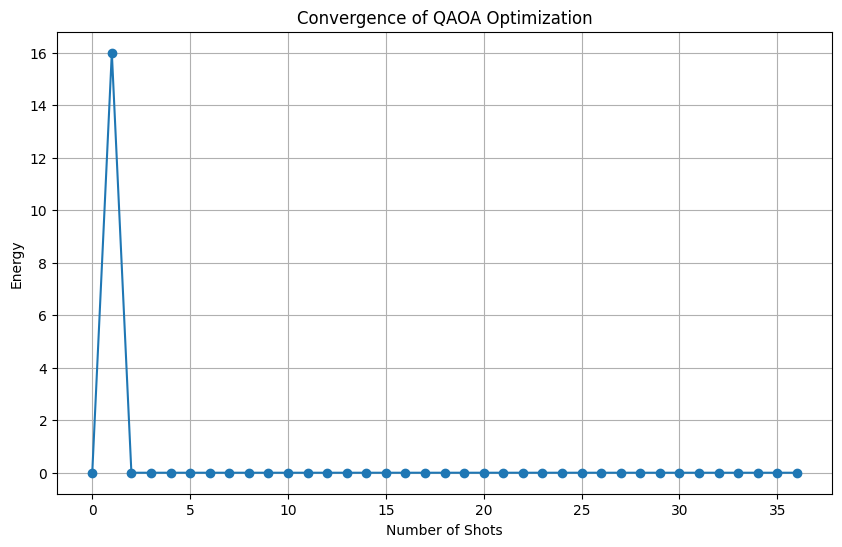

In [15]:
plt.figure(figsize=(10, 6))

plt.plot(vObj, 'o-')
plt.title('Convergence of QAOA Optimization')
plt.xlabel('Number of Shots')
plt.ylabel('Energy')
plt.grid()
plt.show()

### **Best Candidates**

In [16]:
best_sol = min(
    counts.keys(),
    key=lambda x: obj_williamson_8(x)
)

best_obj = obj_williamson_8(best_sol)

print(f"Best bitstring: {best_sol}, Objective function value: {best_obj}")

Best bitstring: 0101, Objective function value: 0


All satisfy

$$s_0 + s_1 + s_2 + s_3 = 0$$

### **Construct Williamson Matrix**

In [17]:
spin = [
    binary_to_spin(int(x))
    for x in best_sol
]

A = np.array([
    [spin[0], spin[0],
     spin[0], spin[0]]
])

B = np.array([
    [spin[1], spin[1],
     spin[1], spin[1]]
])

C = np.array([
    [spin[2], spin[2],
     spin[2], spin[2]]
])

D = np.array([
    [spin[3], spin[3],
     spin[3], spin[3]]
])

print("A:\n", A)
print("B:\n", B)
print("C:\n", C)
print("D:\n", D)

A:
 [[1 1 1 1]]
B:
 [[-1 -1 -1 -1]]
C:
 [[1 1 1 1]]
D:
 [[-1 -1 -1 -1]]


### **Construct Williamson Hadamard Matrix**

In [18]:
def construct_williamson_hadamard(A, B, C, D):
    H = np.block([
        [A, B, C, D],
        [-B, A, -D, C],
        [-C, D, A, -B],
        [-D, -C, B, A]
    ])
    return H

In [19]:
W = construct_williamson_hadamard(A, B, C, D)

print("Williamson Hadamard Matrix:\n", W)

Williamson Hadamard Matrix:
 [[ 1  1  1  1 -1 -1 -1 -1  1  1  1  1 -1 -1 -1 -1]
 [ 1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1]
 [-1 -1 -1 -1 -1 -1 -1 -1  1  1  1  1  1  1  1  1]
 [ 1  1  1  1 -1 -1 -1 -1 -1 -1 -1 -1  1  1  1  1]]


### **Orthogonality Analysis**

In [20]:
DG = np.matmul(W, W.T)
print("Dagger of Williamson Hadamard Matrix:\n", DG)

Dagger of Williamson Hadamard Matrix:
 [[16  0  0  0]
 [ 0 16  0  0]
 [ 0  0 16  0]
 [ 0  0  0 16]]


#### **Visulize Orthogonality**

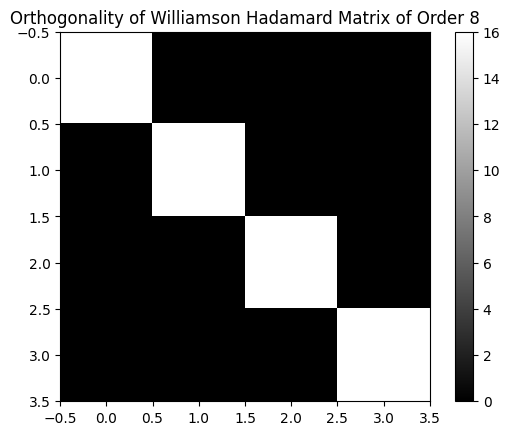

In [21]:
plt.imshow(DG, cmap='gray')

plt.title('Orthogonality of Williamson Hadamard Matrix of Order 8')
plt.colorbar()

plt.show()

### **Visualize Williamson Hadamard Matrix**

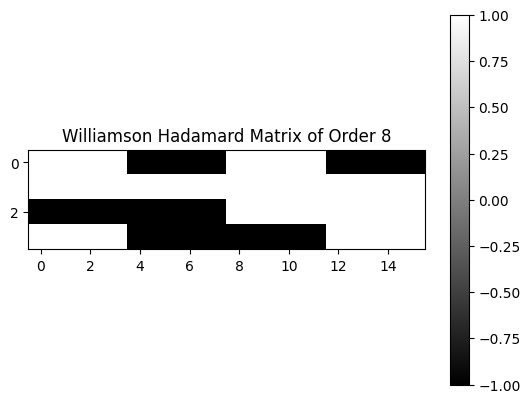

In [22]:
plt.imshow(W, cmap='gray')

plt.title('Williamson Hadamard Matrix of Order 8')
plt.colorbar()

plt.show()

### **Display Results**

In [23]:
print("Best Bitstring:", best_sol)
print("Objective Function Value:", best_obj)
print("Hadamard size:", W.shape)

Best Bitstring: 0101
Objective Function Value: 0
Hadamard size: (4, 16)


### **Discussion and Conclusion**

The order-8 problem requires only four optimization variables and six pairwise interaction terms. The resulting Hamiltonian is purely quadratic, making it considerably simpler than the order-12, order-16, order-20, and order-24 Williamson Hamiltonians. QAOA successfully identifies bitstrings satisfying the Williamson constraint and constructs a valid Hadamard matrix.

This notebook demonstrate the complete QAOA workflow for discovering an order-8 Williamson Hadamard Matrix:
Bistring $⇒$ Spin Variables $⇒$ Hamiltonian $⇒$ QAOA $⇒$ Williamson Construction $⇒$ Hadamard Matrix.

The orthogonality verification confirms 
$$HH^T = 8I_8$$

showing that the generated matrix is a valid Williamson Hadamard matrix of order 8.